# 05: Overfitting va Regularization
Maqsad: model ma'lumotni "yodlab olishi" (overfitting) qanday sodir bo'lishini ko'rish
va undan himoyalanish usullarini o'rganish.

In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline, Pipeline

PolynomialFeatures to'g'ri chiziqni egri chiziqqa aylantiradi. U x dan yangi feature'lar yasaydi: x, x², x³, ... Shunda linear regression ham egri chiziq chiza oladi:

$$y' = b + w_1x + w_2x^2 + w_3x^3 + \dots$$

degree (daraja) qanchalik katta bo'lsa, chiziq shunchalik "egiluvchan" bo'ladi. 3 xil darajani sinab ko'ramiz:

degree=1   train MSE=0.136  test MSE=0.283
degree=3   train MSE=0.038  test MSE=0.067
degree=15  train MSE=0.025  test MSE=0.937


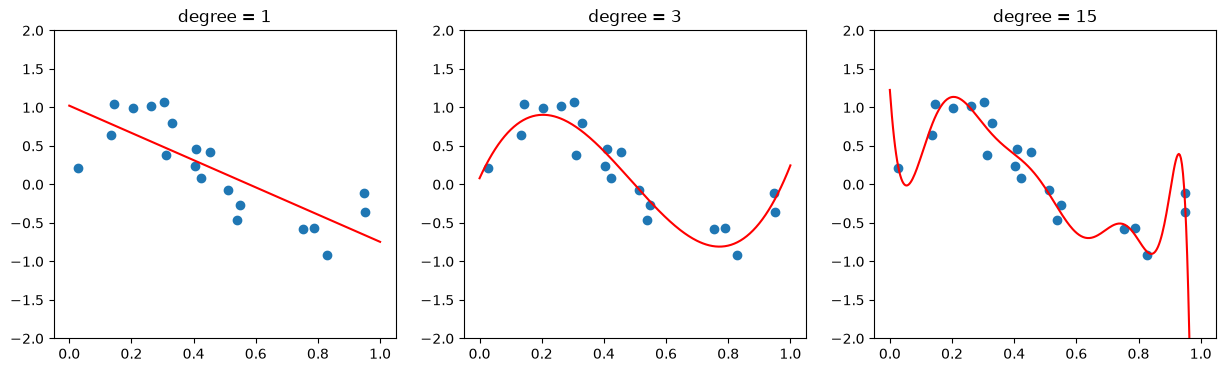

In [8]:
def make_data(n, seed):
    rng = np.random.default_rng(seed)
    x = rng.uniform(0, 1, n)
    y = np.sin(2 * np.pi * x) + rng.normal(0, 0.2, n)
    return x.reshape(-1, 1), y

X_train, y_train = make_data(20, seed=1)    # 20 ta train nuqta
X_test, y_test   = make_data(200, seed=2)   # 200 ta test nuqta

xs = np.linspace(0, 1, 300).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, d in zip(axes, [1, 3, 15]):
    model = make_pipeline(PolynomialFeatures(d), LinearRegression())
    model.fit(X_train, y_train)

    train_mse = mean_squared_error(y_train, model.predict(X_train))
    test_mse  = mean_squared_error(y_test,  model.predict(X_test))
    print(f"degree={d:<3} train MSE={train_mse:.3f}  test MSE={test_mse:.3f}")

    ax.scatter(X_train, y_train)
    ax.plot(xs, model.predict(xs), color="red")
    ax.set_ylim(-2, 2)
    ax.set_title(f"degree = {d}")

plt.show()

Mashq 2: Ridge (L2 Regularization)

📖 Izoh: Overfitting bo'lgan modelda weight'lar odatda juda katta bo'lib ketadi. Chiziq aynan shuning uchun keskin buraladi.

Regularization loss'ga "jarima" qo'shadi: "xatoni kamaytir, lekin weight'larni ham kichik saqla".

$$\text{Loss}_{Ridge} = MSE + \alpha \sum w^2$$
alpha (α) jarima kuchini belgilaydigan hyperparameter
α = 0 → oddiy linear regression
α juda katta → model haddan tashqari "qisiladi", ya'ni underfitting

Degree = 15 ni, ya'ni overfitting bo'lgan modelni olib, unga Ridge qo'shamiz:

alpha=1e-06     train MSE=0.029  test MSE=0.169
alpha=0.001     train MSE=0.030  test MSE=0.122
alpha=1         train MSE=0.084  test MSE=0.170
alpha=10        train MSE=0.112  test MSE=0.236


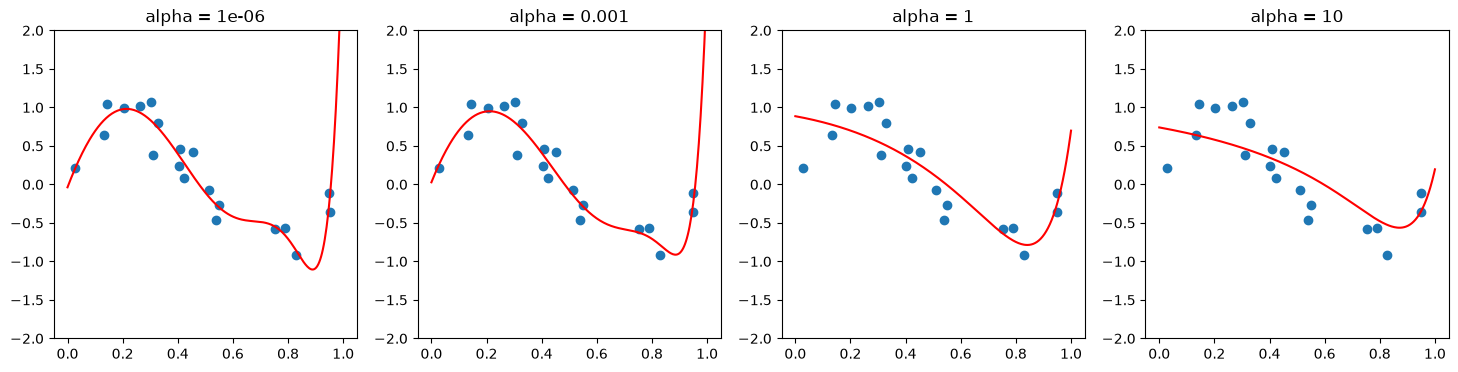

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, alpha in zip(axes, [0.000001, 0.001, 1, 10]):
    model = make_pipeline(PolynomialFeatures(15), StandardScaler(), Ridge(alpha=alpha))
    model.fit(X_train, y_train)

    train_mse = mean_squared_error(y_train, model.predict(X_train))
    test_mse  = mean_squared_error(y_test,  model.predict(X_test))
    print(f"alpha={alpha:<9} train MSE={train_mse:.3f}  test MSE={test_mse:.3f}")

    ax.scatter(X_train, y_train)
    ax.plot(xs, model.predict(xs), color="red")
    ax.set_ylim(-2, 2)
    ax.set_title(f"alpha = {alpha}")

plt.show()

Mashq 3: Lasso (L1 Regularization)

📖 Izoh: Lasso ham jarima qo'shadi, lekin kvadrat o'rniga absolyut qiymatdan foydalanadi:

$$\text{Loss}_{Lasso} = MSE + \alpha \sum |w|$$

Uning o'ziga xos "super kuchi" bor: keraksiz feature'larning weight'ini aynan 0 ga tushiradi, ya'ni ularni modeldan butunlay chiqarib tashlaydi.

Buni tekshirish uchun mpg datasetiga ataylab 2 ta butunlay tasodifiy (foydasiz) ustun qo'shamiz. Lasso ularni topa olarmikin?

In [10]:
df = sns.load_dataset("mpg").dropna()
df["noise1"] = np.random.default_rng(0).normal(size=len(df))   # tasodifiy son
df["noise2"] = np.random.default_rng(1).normal(size=len(df))   # tasodifiy son

features = ["weight", "horsepower", "displacement", "cylinders",
            "model_year", "acceleration", "noise1", "noise2"]
X = df[features]
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr    = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
lasso = make_pipeline(StandardScaler(), Lasso(alpha=0.5)).fit(X_train, y_train)

result = pd.DataFrame({
    "LinearRegression": lr[-1].coef_,
    "Lasso": lasso[-1].coef_,
}, index=features).round(2)

print(result)
print("LinearRegression R²:", round(r2_score(y_test, lr.predict(X_test)), 3))
print("Lasso R²:", round(r2_score(y_test, lasso.predict(X_test)), 3))

              LinearRegression  Lasso
weight                   -5.57  -5.01
horsepower               -0.02  -0.24
displacement              0.09  -0.15
cylinders                -0.17  -0.00
model_year                2.78   2.38
acceleration              0.19   0.00
noise1                    0.16   0.00
noise2                   -0.09  -0.00
LinearRegression R²: 0.793
Lasso R²: 0.805


Mashq 4: Cross-Validation

📖 Izoh: Hozirgacha modelni bitta train/test bo'linishida tekshirdik. Lekin omadimiz kelgan bo'lsa-chi? Test'ga tasodifan "oson" mashinalar tushib qolgan bo'lishi mumkin.

K-Fold Cross-Validation ma'lumotni 5 qismga bo'ladi va modelni 5 marta sinaydi. Har safar boshqa qism test vazifasini bajaradi:

1-sinov: [TEST] [train] [train] [train] [train]
2-sinov: [train] [TEST] [train] [train] [train]
3-sinov: [train] [train] [TEST] [train] [train]
4-sinov: [train] [train] [train] [TEST] [train]
5-sinov: [train] [train] [train] [train] [TEST]
                    ↓
         5 ta natijaning o'rtachasi

shuffle=True muhim: datasetda mashinalar yil bo'yicha tartiblangan, shuning uchun aralashtirmasak, har bir qism faqat ma'lum yillarni o'z ichiga oladi.

In [11]:
num_features = ["weight", "horsepower", "displacement", "cylinders", "model_year"]
X = df[num_features]
y = df["mpg"]

cv = KFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(StandardScaler(), LinearRegression())

scores = cross_val_score(model, X, y, cv=cv, scoring="r2")
print("Har bir sinov:", scores.round(3))
print(f"O'rtacha R² = {scores.mean():.3f} ± {scores.std():.3f}")

Har bir sinov: [0.793 0.806 0.765 0.817 0.832]
O'rtacha R² = 0.803 ± 0.023


Mashq 5: GridSearchCV, ya'ni eng yaxshi hyperparameter'larni avtomatik topish

📖 Izoh: Qaysi degree va qaysi alpha eng yaxshi? Ularni qo'lda birma-bir sinash o'rniga GridSearchCV barcha kombinatsiyalarni cross-validation bilan sinab chiqadi va eng yaxshisini tanlaydi.

3 ta degree × 5 ta alpha = 15 ta kombinatsiya × 5 fold = 75 ta modelni o'zi o'qitadi!

Pipeline ichidagi parametrga murojaat qilish uchun qadam_nomi__parametr (ikkita pastki chiziq) yoziladi.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipe = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),   # 1) avval yangi feature'lar yasaladi
    ("scaler", StandardScaler()),                       # 2) keyin hammasi bir xil masshtabga keltiriladi
    ("model", Ridge()),
])

param_grid = {
    "poly__degree": [1, 2, 3],
    "model__alpha": [0.01, 0.1, 1, 10, 100],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="r2")
grid.fit(X_train, y_train)

print("Eng yaxshi parametrlar:", grid.best_params_)
print(f"Cross-validation R²: {grid.best_score_:.3f}")
print(f"Test R²: {r2_score(y_test, grid.predict(X_test)):.3f}")

Eng yaxshi parametrlar: {'model__alpha': 1, 'poly__degree': 2}
Cross-validation R²: 0.865
Test R²: 0.858
